# Quickstart: US vehicle owner complaints by model, 2010-2025

Owner complaints filed with NHTSA, counted per make, model and model year and split by component. Edition Q3 2026 (NHTSA file dated 2026-08-25).
Cite the Zenodo record [10.5281/zenodo.23685716](https://doi.org/10.5281/zenodo.23685716); the full write-up is the [most complained-about cars report](https://oilandmiles.com/reports/most-complained-cars).

This notebook needs pandas and matplotlib and the CSV in the same folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("nhtsa-complaints-by-model-2010-2025.csv")
print(df.shape)
df.head()

(90254, 6)


,make,model,model_year,component,complaints,year_total
0,Acura,ILX,2013,Air bags,25,66
1,Acura,ILX,2013,Electrical system,14,66
2,Acura,ILX,2013,Power train,9,66
3,Acura,ILX,2013,Engine,6,66
4,Acura,ILX,2013,Service brakes,6,66


## Top 10 vehicles by complaints

`year_total` is the number of complaints for one make, model and model year, so it repeats on every component row of that vehicle. Take it once per vehicle.

In [2]:
vehicles = (df.groupby(["make", "model", "model_year"], as_index=False)["year_total"].first()
              .sort_values("year_total", ascending=False))
vehicles.head(10).reset_index(drop=True)

,make,model,model_year,year_total
0,Ford,Fusion,2010,5126
1,Ford,Focus,2012,3763
2,Hyundai,Sonata,2011,3374
3,Ford,F-150,2013,2975
4,Toyota,Prius,2010,2819
5,Ford,Fusion,2011,2783
6,Ford,Escape,2013,2744
7,Ford,Escape,2017,2663
8,Jeep,Cherokee,2014,2641
9,Ford,Focus,2014,2596


## Components owners named for one vehicle

A complaint can name more than one component, so the component counts add up to more than `year_total`.

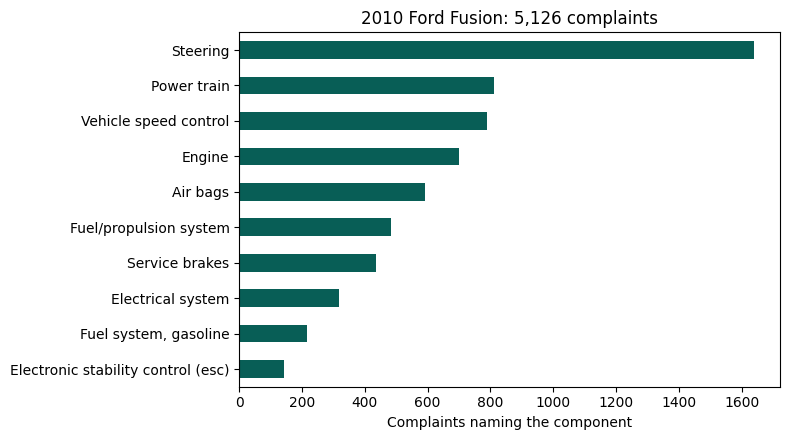

In [3]:
make, model, year = "Ford", "Fusion", 2010
one = df[(df.make == make) & (df.model == model) & (df.model_year == year)].nlargest(10, "complaints")

ax = one.sort_values("complaints").plot.barh(x="component", y="complaints", legend=False, figsize=(8, 4.5), color="#085E56")
ax.set_xlabel("Complaints naming the component")
ax.set_ylabel("")
ax.set_title(f"{year} {make} {model}: {int(one.year_total.iloc[0]):,} complaints")
plt.tight_layout()
plt.show()